# Machine Learning Lab
## Experiment: 8 — Logistic Regression for Customer Churn Prediction

### Objective
Build an end-to-end Logistic Regression pipeline on a synthetic customer-churn dataset, evaluate classification performance, and interpret coefficients as odds ratios.

### Learning outcomes
- Prepare data for a machine-learning workflow.
- Train and evaluate the required model(s).
- Interpret the results rather than relying only on accuracy.

### Environment
Recommended: Python 3.10+ with `numpy`, `pandas`, `matplotlib`, and `scikit-learn`.

## 1. Import libraries
We use a fixed random seed so that the synthetic data and train/test split are reproducible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_auc_score, RocCurveDisplay
)

RANDOM_STATE = 42

## 2. Generate a synthetic dataset of 500 customers
Features:
- `Tenure`: customer tenure in months.
- `MonthlyCharges`: monthly charges in rupees.
- `Churn`: 1 means the customer churned; 0 means the customer stayed.

The target is generated probabilistically from the features. This is simulated data for practice, not real customer evidence.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n = 500

tenure = rng.integers(1, 73, size=n)
monthly_charges = rng.uniform(300, 5000, size=n)

# Construct a probability of churn; longer tenure lowers churn probability.
logit = 1.0 - 0.045 * tenure + 0.00045 * (monthly_charges - 2500)
prob_churn = 1 / (1 + np.exp(-logit))
churn = rng.binomial(1, prob_churn)

df = pd.DataFrame({
    "Tenure": tenure,
    "MonthlyCharges": monthly_charges.round(2),
    "Churn": churn
})
df.head()

,Tenure,MonthlyCharges,Churn
0,7,3364.08,1
1,56,4377.21,0
2,48,2433.32,0
3,32,1464.85,0
4,32,1412.31,0


## 3. Inspect the data
Check shape, data types, missing values, summary statistics, and target balance before modeling.

In [3]:
print("Shape:", df.shape)
display(df.describe().T)
print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\\nChurn distribution:")
display(df["Churn"].value_counts().rename(index={0:"No", 1:"Yes"}))

Shape: (500, 3)


,count,mean,std,min,25%,50%,75%,max
Tenure,500.0,36.44000,20.580513,1.0,19.0000,36.000,54.25,72.00
MonthlyCharges,500.0,2649.43694,1372.810861,305.8,1442.5425,2671.285,3886.84,4995.79
Churn,500.0,0.38400,0.486845,0.0,0.0000,0.000,1.00,1.00


\nMissing values:


,missing_count
Tenure,0
MonthlyCharges,0
Churn,0


\nChurn distribution:


Churn
No     308
Yes    192
Name: count, dtype: int64

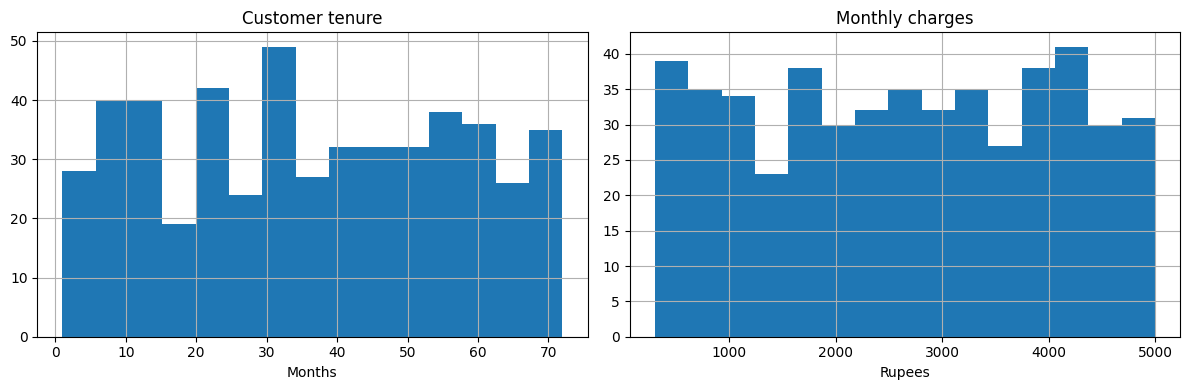

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Tenure"].hist(ax=axes[0], bins=15)
axes[0].set_title("Customer tenure")
axes[0].set_xlabel("Months")
df["MonthlyCharges"].hist(ax=axes[1], bins=15)
axes[1].set_title("Monthly charges")
axes[1].set_xlabel("Rupees")
plt.tight_layout()
plt.show()

## 4. Split the data and build a pipeline
Standardization is useful because the features have different units and scales. The scaler is fitted only on the training data by placing it inside a pipeline.

In [5]:
X = df[["Tenure", "MonthlyCharges"]]
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
model.fit(X_train, y_train)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 375
Testing rows: 125


## 5. Evaluate the model
Use several metrics because accuracy alone may hide poor performance on the minority class.

,Score
Accuracy,0.752000
Precision,0.717949
Recall,0.583333
F1-score,0.643678
ROC-AUC,0.801136


              precision    recall  f1-score   support

    No churn       0.77      0.86      0.81        77
       Churn       0.72      0.58      0.64        48

    accuracy                           0.75       125
   macro avg       0.74      0.72      0.73       125
weighted avg       0.75      0.75      0.75       125



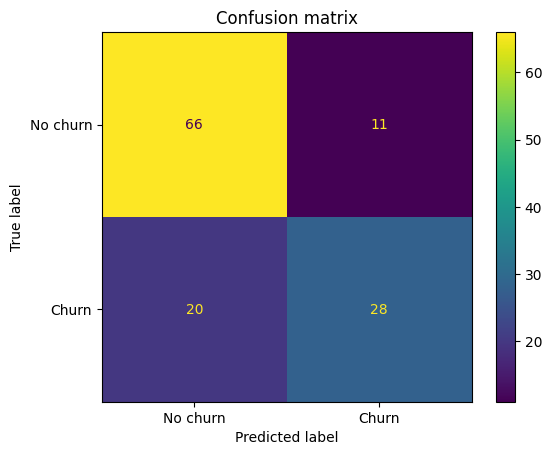

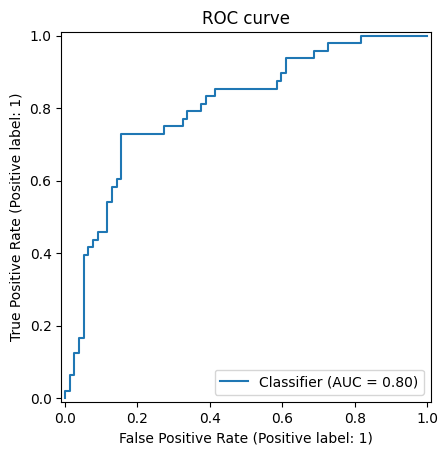

In [6]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
})
display(metrics.to_frame("Score"))
print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No churn", "Churn"])
plt.title("Confusion matrix")
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC curve")
plt.show()

## 6. Interpret coefficients as odds ratios
Because the model uses standardized inputs, coefficients describe a one-standard-deviation increase in each feature. The odds ratio is `exp(coefficient)`.
- Odds ratio greater than 1: the feature is associated with higher modeled odds of churn.
- Odds ratio below 1: the feature is associated with lower modeled odds of churn.
- These are associations in synthetic data, not causal effects.

In [7]:
lr = model.named_steps["logistic_regression"]
coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Standardized coefficient": lr.coef_[0],
    "Odds ratio": np.exp(lr.coef_[0])
}).sort_values("Odds ratio", ascending=False)
display(coef_table)
print("Intercept:", lr.intercept_[0])

,Feature,Standardized coefficient,Odds ratio
1,MonthlyCharges,0.391990,1.479922
0,Tenure,-1.023018,0.359508


Intercept: -0.5952613602001786


## 7. Conclusion
Write a short interpretation using your actual output:
1. How well did the model identify churners?
2. Which metric is most useful for this task, and why?
3. Which feature has the largest modeled association with churn?
4. Why should the results not be generalized to real customers?